### **I.Compréhension de la base de données**

**Objectif:**

**À cette étape, on cherche à répondre à des questions simples :**

**- Combien avons-nous d'observations ?**

**- Quelles sont les variables disponibles ?**

**- Quelles sont leurs types ?**

**- Y a-t-il des valeurs manquantes ?**

**- Y a-t-il des doublons ?**

**- Quelle est la variable cible ?**

In [38]:
# Importation de la bibliothèque pandas
import pandas as pd

# Chargement de la base de données
df = pd.read_excel("Base_client2.xlsx")

In [39]:
# Afficher les 5 premières lignes
print("Voire les premières observations de la base:")
print("==================================================")

print(df.head())

print("==================================================")

# Afficher le nombre de lignes et de colonnes
print("Voire la taille de la base :\n", df.shape)

print("==================================================")

# Afficher les types des variables
print("Voire le type de chaque variable:\n", df.dtypes)

print("==================================================")

# Vérifier les valeurs manquantes
print("Voire les valeurs manquantes:\n", df.isnull().sum())

print("==================================================")

# Vérifier les doublons
print("Voire les doublons:\n", df.duplicated().sum())

print("==================================================")

# Sélection des variables quantitatives
variables_quanti = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Sélection des variables qualitatives
variables_quali = df.select_dtypes(
    include=["str"]
).columns


# Statistiques descriptives des variables quantitatives
description_quanti = df[variables_quanti].describe()

print("Voire la description des variables quantitatives:\n", description_quanti)

print("==================================================")

# Statistiques descriptives des variables qualitatives
for variable in variables_quali:
    

    print("Voire la description des variables qualitatives:\n")
    print("==================================================")
    print("Variable :", variable)
    print("==================================================")
    # Effectifs
    print("Effectifs :")
    print(df[variable].value_counts())

    # Pourcentages
    print("\nPourcentages :")
    print(
        df[variable]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

Voire les premières observations de la base:
          msisdn   sexe categorie_client smartphone multisim  \
0  6823218560306  Homme            jeune        Non      Non   
1  8275742031297  Homme            jeune        Non      Non   
2  5974031051818  Femme            jeune        Non      Non   
3  5639001433904  Femme            jeune        Non      Non   
4  5825190159367  Homme            jeune        Non      Oui   

   anciennete_telco_mois offre_telephonie_fixe  \
0                     34                   Oui   
1                      2                   Oui   
2                      2                   Oui   
3                      8                   Oui   
4                     22                   Oui   

  plusieurs_ligne_telephonie_fixe type_internet services_messageries  \
0                             Non    sobox_fixe                  Oui   
1                             Non    sobox_fixe                  Oui   
2                             Non   sobox_fibre      

In [40]:
data = df.copy()

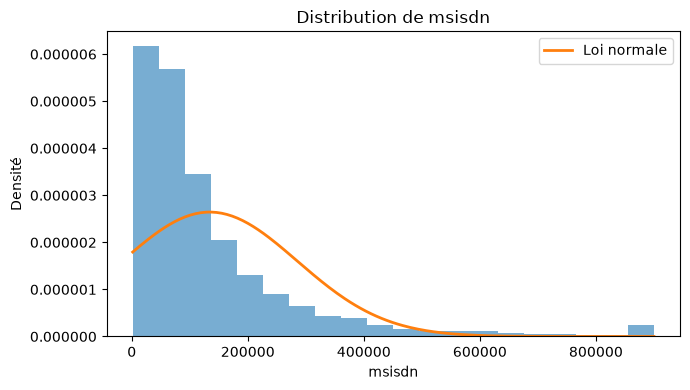

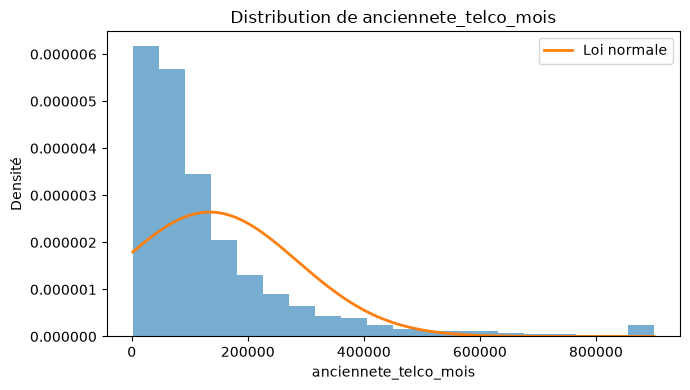

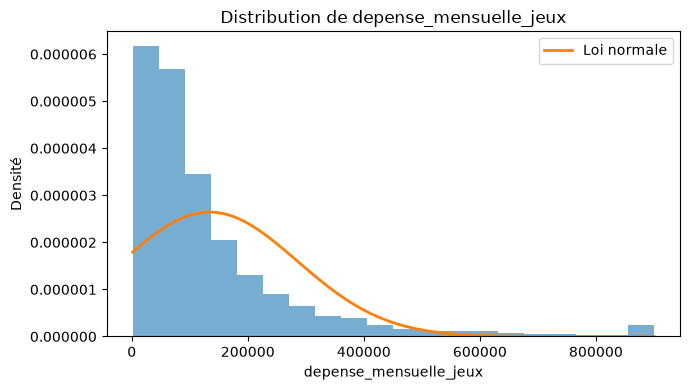

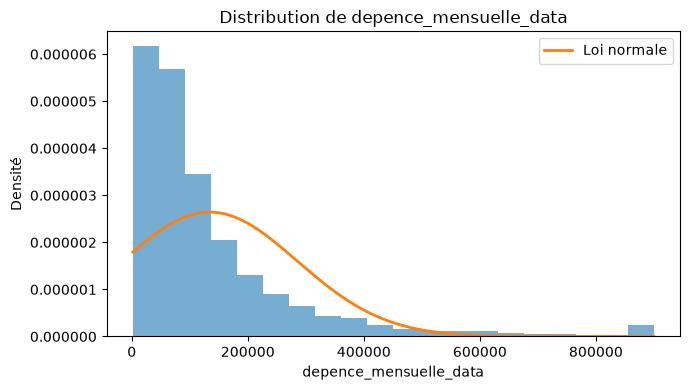

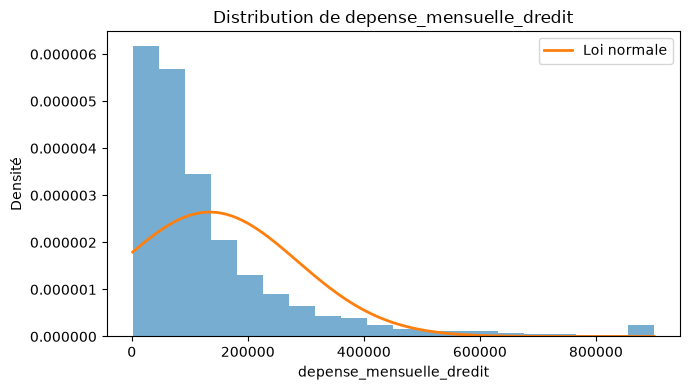

In [41]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from matplotlib.ticker import ScalarFormatter


# Parcourir toutes les variables quantitatives
for variable in variables_quanti:


    # Calculer la moyenne et l'écart-type
    
    moyenne = donnees.mean()
    ecart_type = donnees.std()

    # Créer la figure
    
    plt.figure(figsize=(7, 4))

    # Construire l'histogramme
    
    # density=True permet d'obtenir une densité et donc de pouvoir superposer la loi normale
    plt.hist(
        donnees,
        bins=20,
        density=True,
        alpha=0.6
    )

    #  Créer les valeurs de l'axe X
    
    # On crée 200 valeurs régulièrement espacées
    # entre le minimum et le maximum de la variable
    x = np.linspace(
        donnees.min(),
        donnees.max(),
        200
    )

    # Calculer la densité de la loi normale
    # La loi normale est construite à partir
    # de la moyenne et de l'écart-type observés
    y = norm.pdf(
        x,
        moyenne,
        ecart_type
    )

    # Ajouter la cloche de la loi normale
    plt.plot(
        x,
        y,
        linewidth=2,
        label="Loi normale"
    )

    # Personnaliser le graphique
    
    plt.title(f"Distribution de {variable}")
    plt.xlabel(variable)
    plt.ylabel("Densité")

    # Éviter l'affichage en notation scientifique
    
    # Par exemple, éviter l'affichage de 1e-6
    # sur l'axe des densités
    ax = plt.gca()

    ax.yaxis.set_major_formatter(
        ScalarFormatter(useMathText=False)
    )

    ax.ticklabel_format(
        axis="y",
        style="plain"
    )

    # Afficher la légende
    
    plt.legend()

    # Ajuster automatiquement les marges
   
    plt.tight_layout()

    # Afficher le graphique
    
    plt.show()

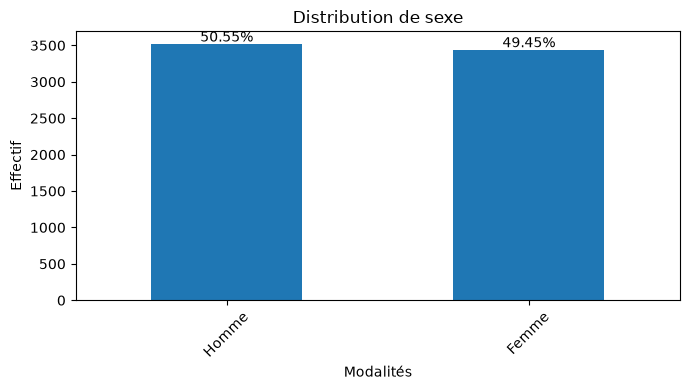

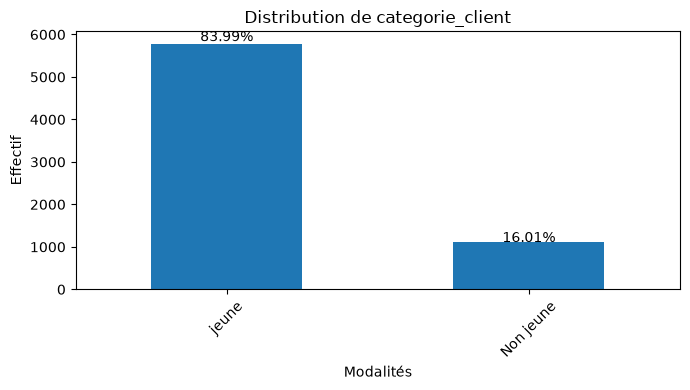

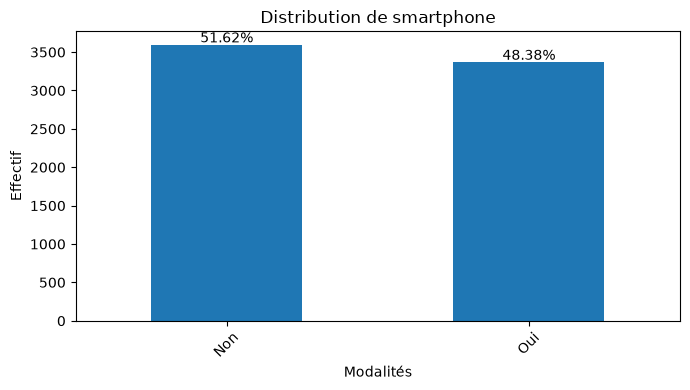

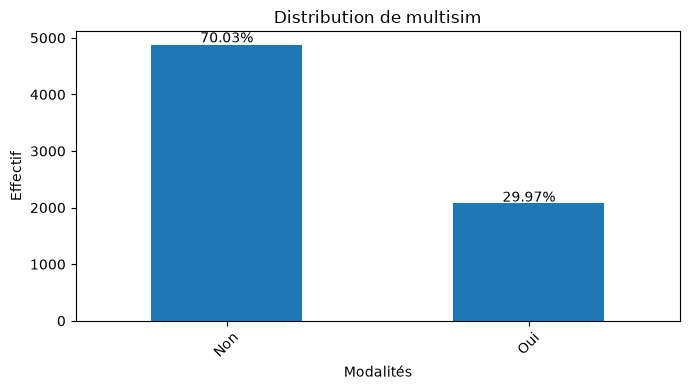

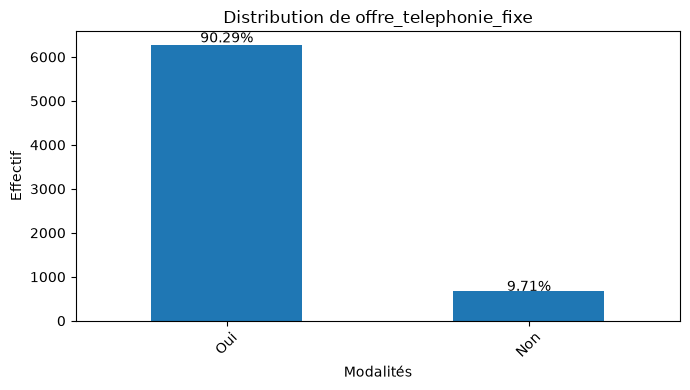

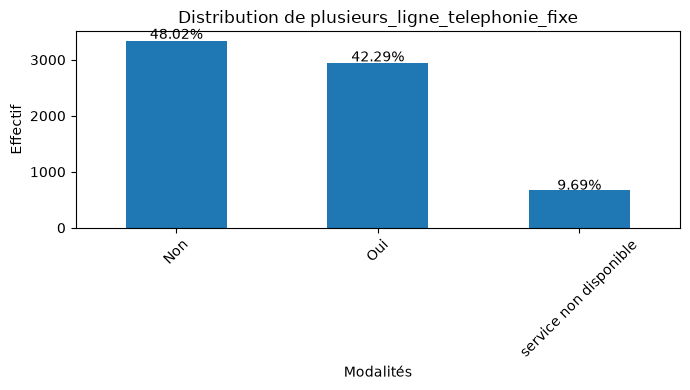

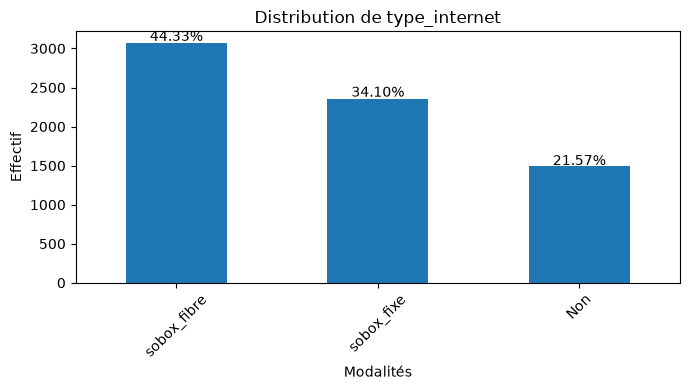

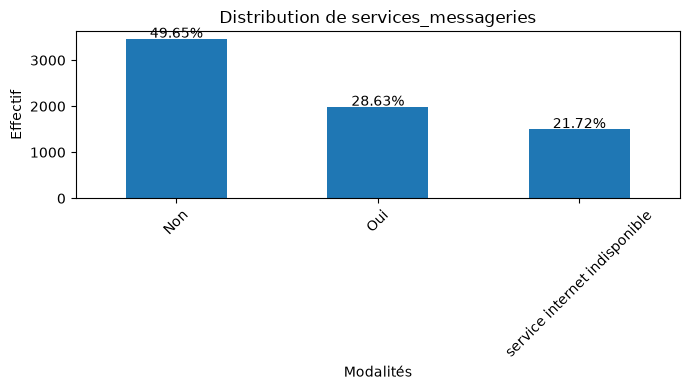

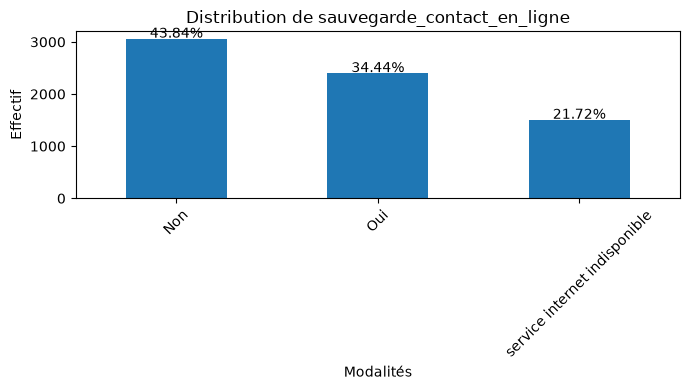

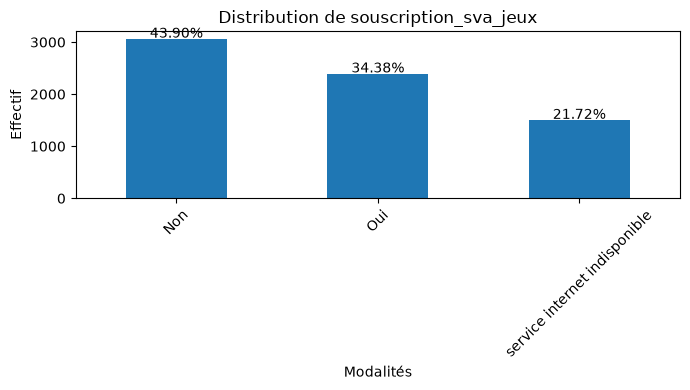

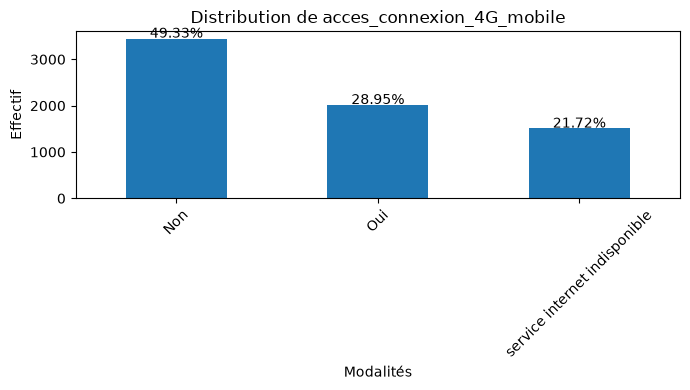

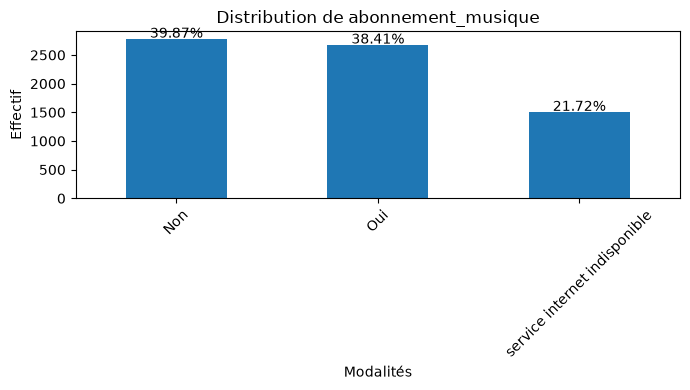

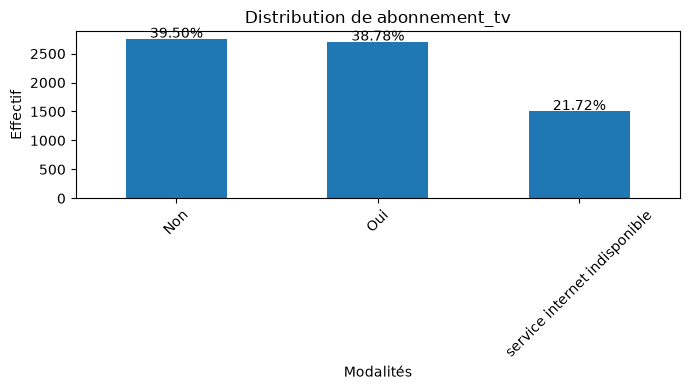

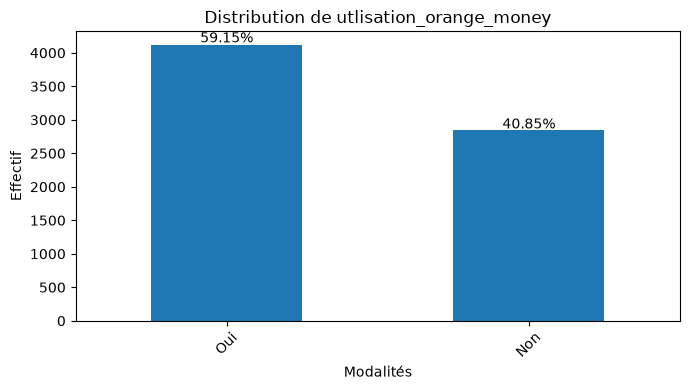

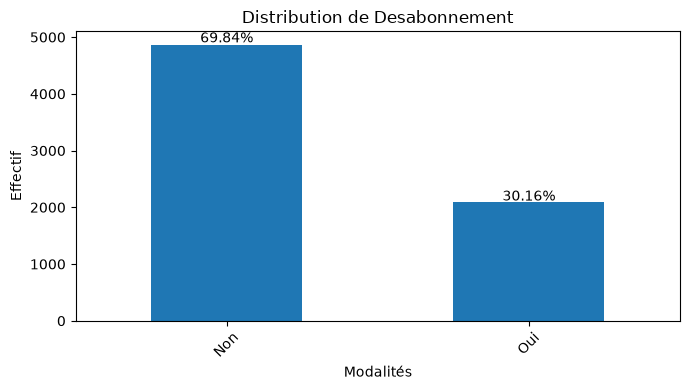

In [42]:
import matplotlib.pyplot as plt

# ==========================================
# VISUALISATION DES VARIABLES QUALITATIVES
# AVEC POURCENTAGES
# ==========================================

for variable in variables_quali:

    # Calcul des effectifs
    effectifs = df[variable].value_counts()

    # Calcul des pourcentages
    pourcentages = df[variable].value_counts(normalize=True) * 100

    # Créer le graphique
    plt.figure(figsize=(7, 4))

    ax = effectifs.plot(kind="bar")

    # Titre et noms des axes
    plt.title(f"Distribution de {variable}")
    plt.xlabel("Modalités")
    plt.ylabel("Effectif")

    # Rotation des modalités
    plt.xticks(rotation=45)

    # Ajouter les pourcentages sur les barres
    for i, (effectif, pourcentage) in enumerate(
        zip(effectifs, pourcentages)
    ):
        ax.text(
            i,
            effectif + effectif * 0.01,
            f"{pourcentage:.2f}%",
            ha="center"
        )

    # Ajuster automatiquement l'espace
    plt.tight_layout()

    # Afficher le graphique
    plt.show()

### **II.Sélection des variables pertinentes**

**L'objectif sera de déterminer quelles variables conserver pour construire le modèle.**

#### **Par la méthode Information mutuelle**

**Elle permet de mesurer la quantité d'information qu'une variable apporte sur la cible et peut détecter des relations non linéaires.**

In [36]:
data = df.copy()

In [43]:
df = df.dropna()

In [44]:
from sklearn.feature_selection import mutual_info_classif

# Variables quantitatives
X_quanti = df[variables_quanti]
y = df['Desabonnement']

# Calcul de l'information mutuelle
mi_quanti = mutual_info_classif(
    X_quanti,
    y,
    random_state=42
)

# Tableau des résultats
resultats_mi_quanti = pd.DataFrame({
    "Variable": variables_quanti,
    "Information_mutuelle": mi_quanti
})

# Trier du plus grand au plus petit
resultats_mi_quanti = resultats_mi_quanti.sort_values(
    by="Information_mutuelle",
    ascending=False
)

print(resultats_mi_quanti)

                   Variable  Information_mutuelle
4  depense_mensuelle_dredit              0.148860
1     anciennete_telco_mois              0.113224
3    depence_mensuelle_data              0.020890
0                    msisdn              0.012956
2    depense_mensuelle_jeux              0.000000


#### **Avec la méthode de la Corrélation entre variables quantitatives**

Matrice de corrélation :
                          msisdn  anciennete_telco_mois  \
msisdn                      1.00                  -0.04   
anciennete_telco_mois      -0.04                   1.00   
depense_mensuelle_jeux     -0.03                  -0.10   
depence_mensuelle_data     -0.01                   0.21   
depense_mensuelle_dredit   -0.03                   0.20   

                          depense_mensuelle_jeux  depence_mensuelle_data  \
msisdn                                     -0.03                   -0.01   
anciennete_telco_mois                      -0.10                    0.21   
depense_mensuelle_jeux                      1.00                   -0.02   
depence_mensuelle_data                     -0.02                    1.00   
depense_mensuelle_dredit                   -0.01                    0.14   

                          depense_mensuelle_dredit  
msisdn                                       -0.03  
anciennete_telco_mois                         0.20  
depe

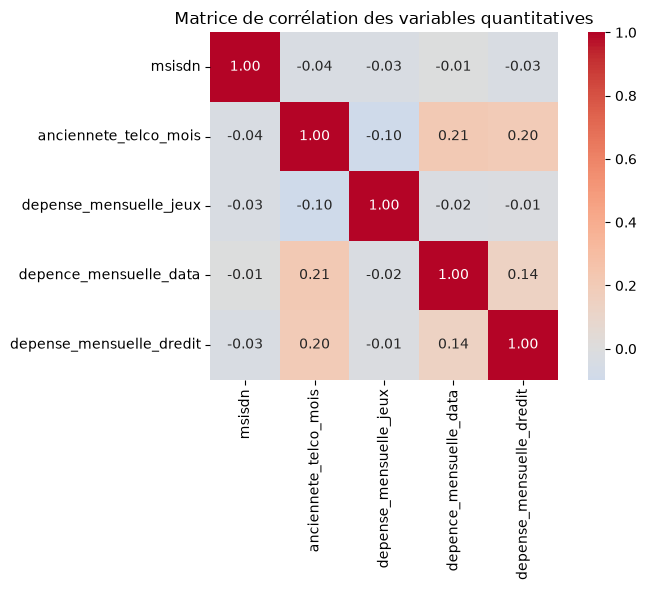

In [ ]:
import seaborn as sns

# ==========================================
# MATRICE DE CORRÉLATION
# POUR LA SÉLECTION DES VARIABLES QUANTITATIVES
# ==========================================

# Calcul de la matrice de corrélation
matrice_corr = df[variables_quanti].corr()

# Afficher la matrice de corrélation
print("Matrice de corrélation :")
print(matrice_corr.round(2))

# ==========================================
# VISUALISATION DE LA MATRICE
# ==========================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    matrice_corr,
    annot=True,          # Afficher les coefficients
    fmt=".2f",           # Deux chiffres après la virgule
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Matrice de corrélation des variables quantitatives")
plt.tight_layout()
plt.show()

**Les deux méthodes utilisées, la matrice de corrélation et l’information mutuelle, sont complémentaires. La matrice de corrélation montre que les variables quantitatives ne présentent pas de forte corrélation entre elles, avec des coefficients compris entre -0,10 et 0,21. Il n’existe donc pas de problème majeur de redondance linéaire entre ces variables. L’information mutuelle permet ensuite d’identifier les variables les plus informatives vis-à-vis du désabonnement. Elle met principalement en évidence depense_mensuelle_dredit (0,148860) et anciennete_telco_mois (0,113224), suivies de depence_mensuelle_data (0,020890). Ainsi, ces trois variables sont retenues pour la modélisation, tandis que msisdn est exclue en tant qu’identifiant et depense_mensuelle_jeux en raison de son information mutuelle nulle et de son fort taux de valeurs manquantes.**

#### **Avec la méthode du Khi-deux pour les qualitatives**

**Pour chaque variable qualitative, on teste son association avec la cible.**

In [47]:
from scipy.stats import chi2_contingency

resultats_khi2 = []

for variable in variables_quali:

    # Tableau croisé entre la variable et la cible
    tableau = pd.crosstab(
        df[variable],
        y
    )

    # Test du Khi-deux
    chi2, p_value, ddl, effectifs_attendus = chi2_contingency(
        tableau
    )

    # Stocker les résultats
    resultats_khi2.append({
        "Variable": variable,
        "Chi2": chi2,
        "p_value": p_value
    })

# Transformer en DataFrame
resultats_khi2 = pd.DataFrame(resultats_khi2)

# Trier selon la p-value
resultats_khi2 = resultats_khi2.sort_values(
    by="p_value"
)

print(resultats_khi2)

                           Variable         Chi2       p_value
14                    Desabonnement  2256.036934  0.000000e+00
2                        smartphone   120.138965  5.898080e-28
12                    abonnement_tv    91.748483  9.842371e-22
8       sauvegarde_contact_en_ligne    89.724830  2.736984e-21
7              services_messageries    83.578195  6.124489e-20
11               abonnement_musique    77.791316  1.145225e-18
3                          multisim    75.424885  3.795757e-18
5   plusieurs_ligne_telephonie_fixe    65.995732  4.668839e-15
10        acces_connexion_4G_mobile    60.599195  6.996263e-15
6                     type_internet    24.871972  6.126673e-07
13          utlisation_orange_money    13.324633  2.619421e-04
1                  categorie_client     2.542901  1.107911e-01
4             offre_telephonie_fixe     1.236677  2.661124e-01
0                              sexe     0.381570  5.367642e-01
9             souscription_sva_jeux     0.000000  1.000

#### **Avec la méthode du V de Cramer**

**Le V de Cramer permet de mesurer la force de l'association.**

In [48]:
import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(tableau):

    # Statistique du Khi-deux
    chi2 = chi2_contingency(tableau)[0]

    # Nombre total d'observations
    n = tableau.sum().sum()

    # Nombre de lignes et colonnes
    r, k = tableau.shape

    # Calcul du V de Cramer
    return np.sqrt(
        (chi2 / n) /
        min(k - 1, r - 1)
    )

In [49]:
resultats_v = []

for variable in variables_quali:

    # Tableau de contingence
    tableau = pd.crosstab(
        df[variable],
        y
    )

    # Calcul du V de Cramer
    v = cramers_v(tableau)

    resultats_v.append({
        "Variable": variable,
        "V_Cramer": v
    })

resultats_v = pd.DataFrame(resultats_v)

# Trier du plus fort au plus faible
resultats_v = resultats_v.sort_values(
    by="V_Cramer",
    ascending=False
)

print(resultats_v)

                           Variable  V_Cramer
14                    Desabonnement  0.998460
2                        smartphone  0.230409
12                    abonnement_tv  0.201353
8       sauvegarde_contact_en_ligne  0.199120
7              services_messageries  0.192178
11               abonnement_musique  0.185406
3                          multisim  0.182564
5   plusieurs_ligne_telephonie_fixe  0.170772
10        acces_connexion_4G_mobile  0.163641
6                     type_internet  0.104837
13          utlisation_orange_money  0.076734
1                  categorie_client  0.033521
4             offre_telephonie_fixe  0.023377
0                              sexe  0.012985
9             souscription_sva_jeux       NaN


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14348\10248016.py:17: RuntimeWarning: invalid value encountered in scalar divide
  (chi2 / n) /


##### **Après sélection de variables on va contruire notre nouvelle base**

**Variables quantitatives retenues:** anciennete_telco_mois ,depence_mensuelle_data et depense_mensuelle_dredit

**Variables qualitatives retenues:** Smartphone, abonnement_tv, sauvegarde_contact_en_ligne, services_messageries ,abonnement_musique, multisim, plusieurs_ligne_telephonie_fixe, acces_connexion_4G_mobile, type_internet et utlisation_orange_money


### **III.Séparation en train et test**

In [50]:
variables_retenues = [
    "anciennete_telco_mois",
    "depence_mensuelle_data",
    "depense_mensuelle_dredit",
    "smartphone",
    "abonnement_tv",
    "sauvegarde_contact_en_ligne",
    "services_messageries",
    "abonnement_musique",
    "multisim",
    "plusieurs_ligne_telephonie_fixe",
    "acces_connexion_4G_mobile",
    "type_internet",
    "utlisation_orange_money"
]

In [52]:
from sklearn.model_selection import train_test_split

#Séparer les variables explicatives X
# et la variable cible y

X = data[variables_retenues].copy()

y = data["Desabonnement"]


# Vérification les dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)


# Séparer en données d'entraînement
# et données de test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # 20 % pour le test
    random_state=42,      # reproductibilité
    stratify=y            # conserve la proportion des classes
)


# 4.3 Vérifier les dimensions

print("\nDimensions des données d'entraînement :")
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("\nDimensions des données de test :")
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

Dimensions de X : (6957, 13)
Dimensions de y : (6957,)

Dimensions des données d'entraînement :
X_train : (5565, 13)
y_train : (5565,)

Dimensions des données de test :
X_test : (1392, 13)
y_test : (1392,)


### **IV.Encodage et mise à l'échelle**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identifier les variables quantitatives et qualitatives

variables_quanti = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

variables_quali = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables quantitatives :")
print(variables_quanti)

print("\nVariables qualitatives :")
print(variables_quali)


# Préparer les transformations

preprocesseur = ColumnTransformer(
    transformers=[
        
        # Mise à l'échelle des variables quantitatives
        (
            "quanti",
            StandardScaler(),
            variables_quanti
        ),
        
        # Encodage One-Hot des variables qualitatives
        (
            "quali",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_quali
        )
    ]
)


# Apprendre les transformations uniquement sur les données d'entraînement

X_train_transforme = preprocesseur.fit_transform(X_train)


# Transformer les données de test avec les mêmes transformations

X_test_transforme = preprocesseur.transform(X_test)


# Vérification

print("\nDimensions avant transformation :")
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("\nDimensions après transformation :")
print("X_train transformé :", X_train_transforme.shape)
print("X_test transformé :", X_test_transforme.shape)

In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


# IDENTIFICATION DES VARIABLES QUANTITATIVES ET QUALITATIVES

variables_quanti = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

variables_quali = X_train.select_dtypes(
    include=["str"]
).columns.tolist()

print("Variables quantitatives :")
print(variables_quanti)

print("\nVariables qualitatives :")
print(variables_quali)


#  PRÉPARATION DES TRANSFORMATIONS

# Pipeline des variables quantitatives
pipeline_quanti = Pipeline([
    
    # Imputation des valeurs manquantes par la médiane
    ("imputation", SimpleImputer(strategy="median")),
    
    # Mise à l'échelle entre 0 et 1
    ("scaling", MinMaxScaler())
])


# Pipeline des variables qualitatives
pipeline_quali = Pipeline([
    
    # Imputation des valeurs manquantes
    # par la modalité la plus fréquente
    ("imputation", SimpleImputer(strategy="most_frequent")),
    
    # Encodage One-Hot
    ("encoding", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


#  CRÉATION DU PRÉPROCESSEUR

preprocesseur = ColumnTransformer(
    transformers=[
        
        # Variables quantitatives :
        # imputation + MinMaxScaler
        (
            "quanti",
            pipeline_quanti,
            variables_quanti
        ),
        
        # Variables qualitatives :
        # imputation + One-Hot Encoding
        (
            "quali",
            pipeline_quali,
            variables_quali
        )
    ]
)


# APPRENTISSAGE SUR LES DONNÉES D'ENTRAÎNEMENT

X_train_transforme = preprocesseur.fit_transform(X_train)


#  TRANSFORMATION DES DONNÉES DE TEST

X_test_transforme = preprocesseur.transform(X_test)


#  VÉRIFICATION DES DIMENSIONS

print("\nDimensions avant transformation :")
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("\nDimensions après transformation :")
print("X_train transformé :", X_train_transforme.shape)
print("X_test transformé :", X_test_transforme.shape)


#  VÉRIFICATION DES VALEURS MANQUANTES

print("\nValeurs manquantes après transformation :")
print("X_train :", np.isnan(X_train_transforme).sum())
print("X_test :", np.isnan(X_test_transforme).sum())

Variables quantitatives :
['anciennete_telco_mois', 'depence_mensuelle_data', 'depense_mensuelle_dredit']

Variables qualitatives :
['smartphone', 'abonnement_tv', 'sauvegarde_contact_en_ligne', 'services_messageries', 'abonnement_musique', 'multisim', 'plusieurs_ligne_telephonie_fixe', 'acces_connexion_4G_mobile', 'type_internet', 'utlisation_orange_money']

Dimensions avant transformation :
X_train : (5565, 13)
X_test : (1392, 13)

Dimensions après transformation :
X_train transformé : (5565, 30)
X_test transformé : (1392, 30)

Valeurs manquantes après transformation :
X_train : 0
X_test : 0


In [64]:
# ENCODAGE DE LA VARIABLE CIBLE

# Transformer la variable cible en 0 et 1
y_train = y_train.map({
    "Non": 0,
    "Oui": 1
})

y_test = y_test.map({
    "Non": 0,
    "Oui": 1
})


# Vérification
print("Valeurs de y_train :")
print(y_train.value_counts())

print("\nValeurs de y_test :")
print(y_test.value_counts())

Valeurs de y_train :
Desabonnement
0    3887
1    1678
Name: count, dtype: int64

Valeurs de y_test :
Desabonnement
0    972
1    420
Name: count, dtype: int64


### **V.Entraînement du modèle**

In [65]:
from sklearn.linear_model import LogisticRegression

# Créer le modèle

modele = LogisticRegression(
    random_state=42,
    max_iter=200
)


# Entraîner le modèle

modele.fit(
    X_train_transforme,
    y_train
)


# Vérifier que le modèle est entraîné

print("Modèle entraîné avec succès.")

Modèle entraîné avec succès.


### **VI.Évaluation du modèle**

In [73]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

# Prédictions des classes
y_pred = modele.predict(X_test_transforme)

# Probabilités de la classe 1 = désabonnement
y_proba = modele.predict_proba(X_test_transforme)[:, 1]

# Probabilité de désabonnement = classe 1
probabilite_desabonnement = y_proba

# MATRICE DE CONFUSION

matrice = confusion_matrix(y_test, y_pred)

print("Matrice de confusion :")
print(matrice)


# CALCUL DES MÉTRIQUES

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

# AUC-ROC
auc_roc = roc_auc_score(y_test, y_proba)


# AFFICHAGE DES RÉSULTATS

print("\nRésultats du modèle :")
print("Accuracy  :", round(accuracy, 4))
print("Précision :", round(precision, 4))
print("Rappel    :", round(recall, 4))
print("F1-score  :", round(f1, 4))
print("AUC-ROC   :", round(auc_roc, 4))


# RAPPORT DE CLASSIFICATION

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

Matrice de confusion :
[[895  77]
 [ 85 335]]

Résultats du modèle :
Accuracy  : 0.8836
Précision : 0.8131
Rappel    : 0.7976
F1-score  : 0.8053
AUC-ROC   : 0.9471

Rapport de classification :
              precision    recall  f1-score   support

           0       0.91      0.92      0.92       972
           1       0.81      0.80      0.81       420

    accuracy                           0.88      1392
   macro avg       0.86      0.86      0.86      1392
weighted avg       0.88      0.88      0.88      1392



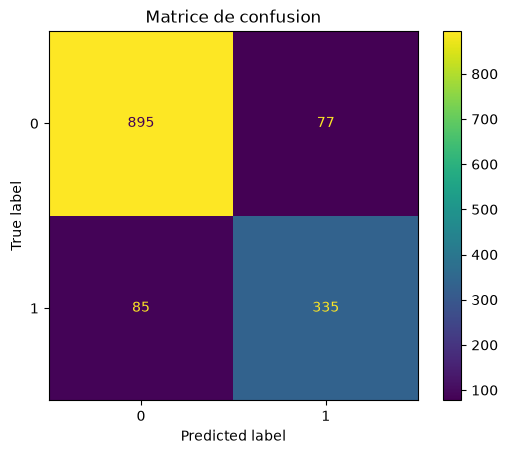

In [74]:
# Visualisation de la matrice de confusion

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Matrice de confusion")
plt.show()

#### **Enregistrement de la base avec les proba et la décision**

In [75]:
# PRÉDICTIONS ET PROBABILITÉS

# Probabilité des deux classes
y_proba = modele.predict_proba(X_test_transforme)

# Probabilité de non-désabonnement
probabilite_non = y_proba[:, 0]

# Probabilité de désabonnement
probabilite_oui = y_proba[:, 1]

# Classe prédite
y_pred = modele.predict(X_test_transforme)


# CRÉATION DE LA BASE À EXPORTER

# Copier les variables retenues de la base test
base_export = X_test.copy()

# Ajouter la vraie classe
base_export["Desabonnement_reel"] = y_test.values

# Ajouter les probabilités
base_export["Probabilite_Non"] = probabilite_non
base_export["Probabilite_Oui"] = probabilite_oui

# Ajouter la décision du modèle
base_export["Decision"] = y_pred


# CONVERSION DES PROBABILITÉS EN POURCENTAGE

base_export["Probabilite_Non"] = (
    base_export["Probabilite_Non"] * 100
).round(2)

base_export["Probabilite_Oui"] = (
    base_export["Probabilite_Oui"] * 100
).round(2)


# EXPORTATION AU FORMAT EXCEL

nom_fichier = "base_test_prediction_regression_logistique.xlsx"

base_export.to_excel(
    nom_fichier,
    index=False
)


#  VÉRIFICATION

print("Fichier enregistré :", nom_fichier)
print("Dimensions :", base_export.shape)

print("\nAperçu de la base :")
print(base_export.head(10))

Fichier enregistré : base_test_prediction_regression_logistique.xlsx
Dimensions : (1392, 17)

Aperçu de la base :
      anciennete_telco_mois  depence_mensuelle_data  depense_mensuelle_dredit  \
4807                     38                  4712.0                  117412.0   
829                       1                  2384.0                  131428.0   
6631                     28                     NaN                   19233.0   
6446                     49                  6634.0                  165654.0   
5827                     49                  5686.0                   47766.0   
1934                     53                  6867.0                  247547.0   
522                      70                  1714.0                  222167.0   
1981                     10                  4363.0                   33333.0   
6532                      3                  2264.0                   38530.0   
2717                      5                  3628.0                   62961.

### **VII.Validation croisée**

**Pour une classification, on peut utiliser StratifiedKFold afin de conserver la proportion des classes dans chaque pli.**

In [77]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Créer le modèle

modele = LogisticRegression(
    random_state=42,
    max_iter=200
)


# Créer le Pipeline

pipeline = Pipeline([
    
    # Étape 1 : prétraitement
    ("preprocesseur", preprocesseur),
    
    # Étape 2 : modèle
    ("modele", modele)
])


#  Définir la validation croisée

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


#Effectuer la validation croisée

scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)


# Afficher les résultats

print("Scores F1 pour chaque pli :")
print(scores)

print("\nF1 moyen :", round(scores.mean(), 4))

print("Écart-type :", round(scores.std(), 4))

Scores F1 pour chaque pli :
[0.81426449 0.80418535 0.78157504 0.79389313 0.81538462]

F1 moyen : 0.8019
Écart-type : 0.0128


### **VIII.Ajustement des hyperparamètres**

In [78]:
from sklearn.model_selection import GridSearchCV

#Définir les paramètres à tester

parametres = {
    "modele__C": [0.01, 0.1, 1, 10, 100],
    "modele__solver": ["liblinear", "lbfgs"]
}


#Créer GridSearchCV

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parametres,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)


# Lancer la recherche

grid_search.fit(X_train, y_train)


# Afficher les meilleurs paramètres

print("Meilleurs paramètres :")
print(grid_search.best_params_)


#  Afficher le meilleur score

print("\nMeilleur F1-score :")
print(round(grid_search.best_score_, 4))

Meilleurs paramètres :
{'modele__C': 100, 'modele__solver': 'lbfgs'}

Meilleur F1-score :
0.8194


In [80]:
# Prédictions sur le jeu de test
meilleur_modele = grid_search.best_estimator_

y_pred_final = meilleur_modele.predict(X_test)


# Évaluation finale

print("Accuracy  :", round(
    accuracy_score(y_test, y_pred_final), 4
))

print("Précision :", round(
    precision_score(y_test, y_pred_final), 4
))

print("Rappel    :", round(
    recall_score(y_test, y_pred_final), 4
))

print("F1-score  :", round(
    f1_score(y_test, y_pred_final), 4
))


print("\nRapport de classification :")
print(
    classification_report(
        y_test,
        y_pred_final
    )
)

Accuracy  : 0.8872
Précision : 0.8169
Rappel    : 0.8071
F1-score  : 0.812

Rapport de classification :
              precision    recall  f1-score   support

           0       0.92      0.92      0.92       972
           1       0.82      0.81      0.81       420

    accuracy                           0.89      1392
   macro avg       0.87      0.86      0.87      1392
weighted avg       0.89      0.89      0.89      1392



#### **Enregistrement du modèle final**